# 16 — MURA all-anatomy peripheral-pixel sensitivity audit

This is a bounded diagnostic of the saved fine-tuned models. It does not retrain a model, select a threshold, or make a lesion-localization claim.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

def locate_project_root():
    for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (candidate / "CHARTER.md").exists():
            return candidate
    raise RuntimeError("Run this notebook from inside the repository checkout.")

ROOT = locate_project_root()
RUNTIME = ROOT.parent / 'runtime' / 'multianatomy_v1'
FINE = RUNTIME / 'finetuned_all_v1'
COMPARISON = RUNTIME / 'model_comparison_v1'
SHORTCUT = RUNTIME / 'shortcut_audit_v1'
assert ROOT.name == 'mura-wrist-ml-pipeline', ROOT
print('Notebook environment configured; results are loaded from saved development artifacts.')


Notebook environment configured; results are loaded from saved development artifacts.


In [2]:
provenance = json.loads((SHORTCUT / 'shortcut_audit_provenance.json').read_text(encoding='utf-8'))
assert provenance['official_valid_read'] is False
assert provenance['test_used_for_selection'] is False
assert provenance['threshold_reselected'] is False
display(Markdown('**Audit scope:** saved internal-validation checkpoints and frozen validation thresholds only.'))
display(pd.DataFrame([provenance]))

**Audit scope:** saved internal-validation checkpoints and frozen validation thresholds only.

,scope,official_valid_read,test_used_for_selection,threshold_reselected,variants,canonical_prediction_tolerance,bootstrap_unit,bootstrap_replicates,detailed_rows_local_only
0,development-only internal validation periphera...,False,False,False,"[canonical, padding_midgray, outer_border_blac...",0.00001,patient,2000,True


,anatomy,variant,mean_abs_probability_change,median_abs_probability_change,p95_abs_probability_change,decision_flip_count,decision_flip_percent,new_false_negatives_after_perturbation,new_false_positives_after_perturbation
1,XR_ELBOW,four_corner_mask_black_10pct,0.0037,0.0000,0.0208,4,1.1594,0,2
2,XR_ELBOW,outer_border_black_5pct,0.0343,0.0126,0.1344,21,6.0870,1,11
3,XR_ELBOW,padding_midgray,0.0541,0.0221,0.1892,29,8.4058,0,27
5,XR_FINGER,four_corner_mask_black_10pct,0.0004,0.0000,0.0000,0,0.0000,0,0
6,XR_FINGER,outer_border_black_5pct,0.1268,0.0323,0.4769,32,8.1633,5,3
7,XR_FINGER,padding_midgray,0.1308,0.0406,0.5184,44,11.2245,7,7
9,XR_FOREARM,four_corner_mask_black_10pct,0.0037,0.0007,0.0171,3,1.6393,0,1
10,XR_FOREARM,outer_border_black_5pct,0.0533,0.0387,0.1483,12,6.5574,0,2
11,XR_FOREARM,padding_midgray,0.1150,0.0804,0.3717,43,23.4973,5,2
13,XR_HAND,four_corner_mask_black_10pct,0.0009,0.0000,0.0025,3,0.7299,1,2


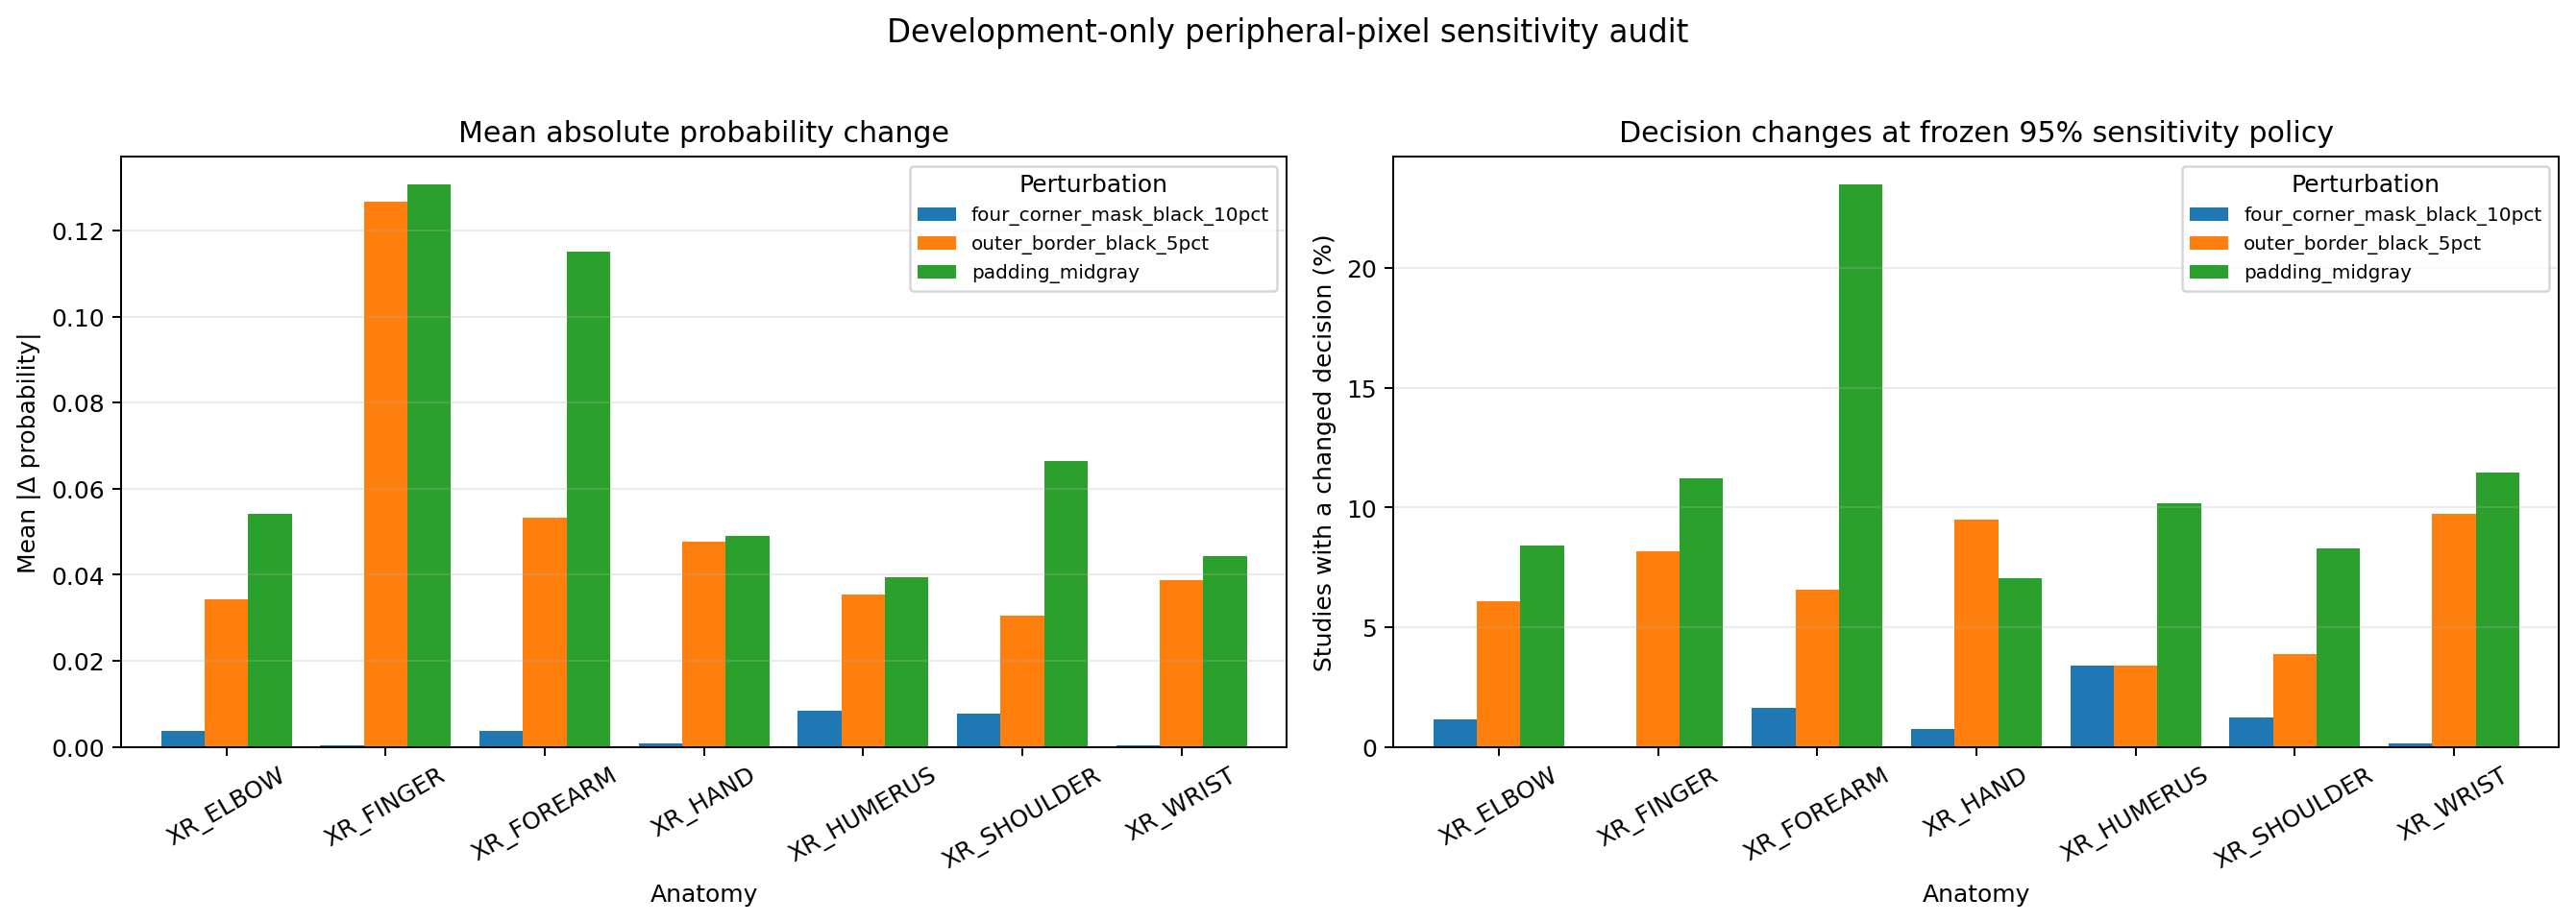

In [3]:
summary = pd.read_csv(SHORTCUT / 'MULTI_ANATOMY_SHORTCUT_AUDIT_SUMMARY.csv')
shown = summary[summary['variant'] != 'canonical']
display(shown[[
    'anatomy', 'variant', 'mean_abs_probability_change', 'median_abs_probability_change',
    'p95_abs_probability_change', 'decision_flip_count', 'decision_flip_percent',
    'new_false_negatives_after_perturbation', 'new_false_positives_after_perturbation'
]].round(4))
display(Image(filename=str(SHORTCUT / 'shortcut_audit_summary.png')))

In [4]:
intervals = pd.read_csv(SHORTCUT / 'shortcut_audit_bootstrap_ci.csv')
display(intervals[['anatomy', 'variant', 'metric', 'point_estimate', 'lower_95_ci', 'upper_95_ci', 'valid_resamples']].round(4))

,anatomy,variant,metric,point_estimate,lower_95_ci,upper_95_ci,valid_resamples
0,XR_ELBOW,four_corner_mask_black_10pct,decision_flip_percent,1.1594,0.2874,2.3462,2000
1,XR_ELBOW,four_corner_mask_black_10pct,mean_abs_probability_change,0.0037,0.0028,0.0048,2000
2,XR_ELBOW,outer_border_black_5pct,decision_flip_percent,6.0870,3.7464,8.7212,2000
3,XR_ELBOW,outer_border_black_5pct,mean_abs_probability_change,0.0343,0.0289,0.0401,2000
4,XR_ELBOW,padding_midgray,decision_flip_percent,8.4058,5.7139,11.4613,2000
5,XR_ELBOW,padding_midgray,mean_abs_probability_change,0.0541,0.0460,0.0633,2000
6,XR_FINGER,four_corner_mask_black_10pct,decision_flip_percent,0.0000,0.0000,0.0000,2000
7,XR_FINGER,four_corner_mask_black_10pct,mean_abs_probability_change,0.0004,0.0001,0.0006,2000
8,XR_FINGER,outer_border_black_5pct,decision_flip_percent,8.1633,5.6929,10.8312,2000
9,XR_FINGER,outer_border_black_5pct,mean_abs_probability_change,0.1268,0.1102,0.1429,2000


### Interpretation boundary

The perturbations measure sensitivity to synthetic padding, borders, and corners. They do **not** identify a specific L/R marker, prove shortcut learning, prove lesion localization, or prove that a model is free of shortcuts. A border or corner can include anatomy, collimation, or acquisition content. The detailed per-study rows remain local and are not part of this notebook.